# 01 · Exploring real eCommerce data (Conjura)

**Goal:** find out whether any brand in this dataset is fit for a media mix model, and
what problems real data brings that our synthetic data didn't.

**Data:** Anderson, A. (2024). *Multi-Region Marketing Mix Modelling (MMM) Dataset for
Several eCommerce Brands.* figshare. [doi:10.6084/m9.figshare.25314841.v3](https://doi.org/10.6084/m9.figshare.25314841.v3).
CC BY 4.0. It's anonymised, real data from close to 100 online brands. Fetch it with
`scripts/download_conjura.sh`.

**What an MMM needs:**
1. enough history (3+ years of weeks)
2. spend that **varies independently**: not flat, not just following the trend, and
   channels not moving in lockstep
3. ad spend large enough relative to revenue for its effect to stand out from noise

The logic lives in `src/mbc/realdata/conjura.py`. This notebook only calls it and looks
at the results.

In [1]:
import mbc  # must come first: sets the PyTensor compiler fix on macOS

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from mbc.plotting import REAL_CHANNEL_COLORS, TEXT_SECONDARY, apply_style
from mbc.realdata.conjura import (
    ORGANIC_COLS, SPEND_COLS, load_raw, mmm_candidates, screen_series, to_weekly,
)

apply_style()
%matplotlib inline
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 2)
money = FuncFormatter(lambda x, _: f"{x/1000:,.0f}k")

## 1. What's in the file?

One row = one **day** for one **time series**. A series is a brand, sometimes split by
country (`territory_name`). A single brand can therefore appear several times: once
for "All Territories" and once per big country.

In [2]:
daily = load_raw()
print(f"{len(daily):,} rows | {daily.mmm_timeseries_id.nunique()} series | "
      f"{daily.organisation_id.nunique()} brands | "
      f"{daily.date_day.min():%Y-%m-%d} to {daily.date_day.max():%Y-%m-%d}")
daily.groupby("mmm_timeseries_id").date_day.count().describe().round(0).to_frame("days per series").T

132,759 rows | 143 series | 93 brands | 2019-07-21 to 2024-06-02


,count,mean,std,min,25%,50%,75%,max
days per series,143.0,928.0,374.0,451.0,593.0,872.0,1202.0,1751.0


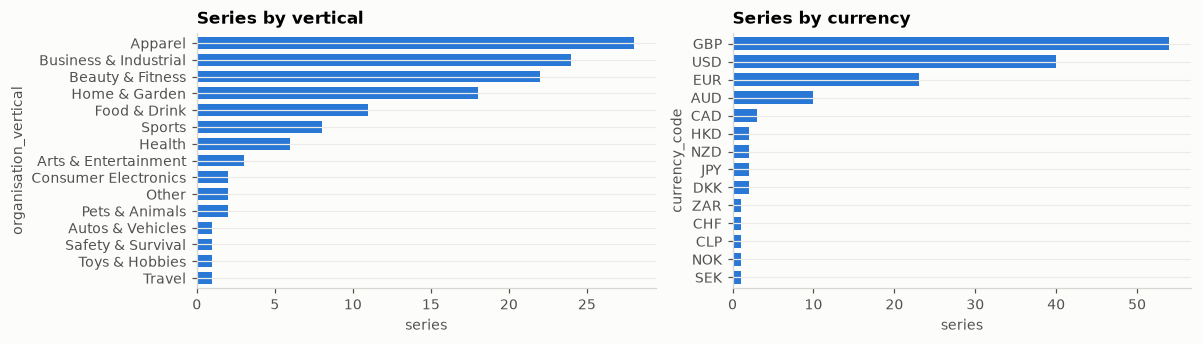

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
daily.groupby("mmm_timeseries_id").organisation_vertical.first().value_counts().sort_values().plot.barh(
    ax=axes[0], color="#2a78d6", width=0.7)
axes[0].set_title("Series by vertical"); axes[0].set_xlabel("series"); axes[0].grid(axis="x")
daily.groupby("mmm_timeseries_id").currency_code.first().value_counts().sort_values().plot.barh(
    ax=axes[1], color="#2a78d6", width=0.7)
axes[1].set_title("Series by currency"); axes[1].set_xlabel("series"); axes[1].grid(axis="x")
fig.tight_layout()

**Currency matters.** Each series reports money in its own currency, so we never mix
series without converting. That's the reason we model **one series at a time**.

## 2. Which channels do brands actually use?

A missing spend value means the channel isn't used in that series. `load_raw` turns it
into 0.

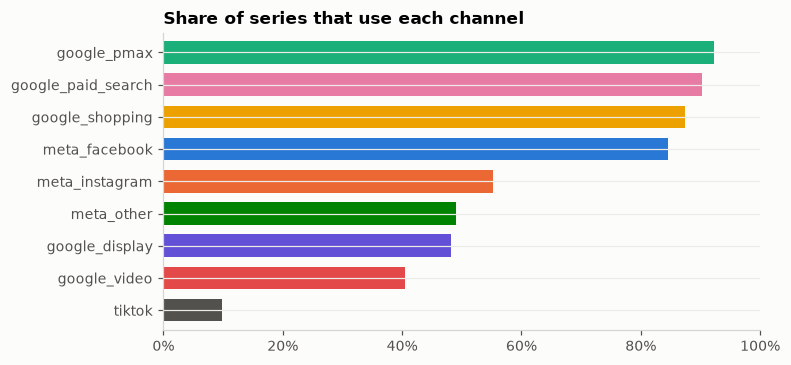

In [4]:
per_series = daily.groupby("mmm_timeseries_id")[SPEND_COLS].sum()
usage = (per_series > 0).mean().sort_values()
share = per_series.sum().div(per_series.sum().sum())  # only meaningful within a currency; rough view
ax = usage.rename(lambda c: c.removesuffix("_spend")).plot.barh(
    figsize=(7, 3.5), color=[REAL_CHANNEL_COLORS[c.removesuffix("_spend")] for c in usage.index], width=0.7)
ax.set_title("Share of series that use each channel"); ax.set_xlim(0, 1); ax.grid(axis="x")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

## 3. From days to weeks

MMMs are usually fitted on **weekly** data:
- Daily data is noisy (weekday patterns, payday effects) and has many more data points
  to fit without much more information about the media effects.
- Adstock at a weekly grain needs fewer lags.

`to_weekly` keeps only **complete** Monday-to-Sunday weeks. A partial first or last
week looks like a sudden drop in both spend and revenue, and the model would read that
as an ad effect.

In [5]:
weekly = to_weekly(daily)
print(f"{len(weekly):,} series-weeks")
weekly.head(3)

18,859 series-weeks


,mmm_timeseries_id,week,revenue,orders,new_customer_orders,google_paid_search_spend,google_shopping_spend,google_pmax_spend,google_display_spend,google_video_spend,meta_facebook_spend,meta_instagram_spend,meta_other_spend,tiktok_spend,direct_clicks,branded_search_clicks,organic_search_clicks,email_clicks,referral_clicks,all_other_clicks,organisation_id,organisation_vertical,organisation_subvertical,territory_name,currency_code
0,000735021aa3b94ec319dbe83d137874,2022-05-30,3309.00,18,14,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.0,0.0,232.0,0.0,293.0,10.0,96.0,106.0,8d85172419d0499b1e601c1a4e9b0a45,Home & Garden,Nursery & Playroom,All Territories,USD
1,000735021aa3b94ec319dbe83d137874,2022-06-06,4136.15,18,14,0.0,0.00,1602.55,0.0,0.0,0.00,0.0,0.0,0.0,3139.0,70.0,212.0,17.0,38.0,206.0,8d85172419d0499b1e601c1a4e9b0a45,Home & Garden,Nursery & Playroom,All Territories,USD
2,000735021aa3b94ec319dbe83d137874,2022-06-13,2286.00,11,10,0.0,13.67,1419.37,0.0,0.0,1148.87,0.0,0.0,19.6,1134.0,97.0,164.0,23.0,71.0,230.0,8d85172419d0499b1e601c1a4e9b0a45,Home & Garden,Nursery & Playroom,All Territories,USD


## 4. Screening: which series could support an MMM?

`screen_series` computes, per series:

| column | question it answers | why it matters |
|---|---|---|
| `weeks` | is there enough history? | seasonality needs several years to separate from media |
| `main_channels` | which channels get ≥10% of spend? | tiny channels can't be estimated; we'd merge or drop them |
| `spend_to_revenue` | is advertising a big enough lever? | at 0.5% of revenue, the ad effect is buried in noise |
| `min_cv` | does spend **vary**? (std ÷ mean) | a flat budget carries no information about its effect |
| `max_trend_corr` | does spend just follow time? | then "ads grew sales" and "sales grew anyway" are indistinguishable |
| `max_pair_corr` | do two channels move together? | then the model can't split credit between them |

In [6]:
screen = screen_series(weekly)
cands = mmm_candidates(screen)  # >=156 weeks, >=2 main channels, min_cv >= 0.3, spend >= 2% of revenue
print(f"{len(cands)} of {len(screen)} series pass the basic screen")
cands[["mmm_timeseries_id", "vertical", "territory", "currency", "weeks", "spend_to_revenue",
       "main_channels", "min_cv", "max_trend_corr", "max_pair_corr"]].assign(
    mmm_timeseries_id=lambda d: d.mmm_timeseries_id.str[:8])

33 of 142 series pass the basic screen


,mmm_timeseries_id,vertical,territory,currency,weeks,spend_to_revenue,main_channels,min_cv,max_trend_corr,max_pair_corr
0,cb746966,Autos & Vehicles,All Territories,USD,249,0.07,"google_paid_search, google_shopping, google_pmax",0.44,0.83,0.69
1,79d11f29,Beauty & Fitness,All Territories,GBP,244,0.03,"google_shopping, google_pmax",0.43,0.63,0.09
2,68361a5f,Beauty & Fitness,Germany,EUR,244,0.04,"google_shopping, google_pmax",0.49,0.55,0.09
3,36558b27,Home & Garden,All Territories,GBP,236,0.04,"google_paid_search, google_shopping, google_pmax",0.70,0.73,0.76
4,ce6be55b,Home & Garden,All Territories,GBP,234,0.15,"google_paid_search, google_pmax, meta_facebook",0.72,0.75,0.59
5,37dc4128,Business & Industrial,Germany,EUR,230,0.04,"google_shopping, google_pmax",0.45,0.48,0.07
6,51c8843b,Business & Industrial,All Territories,GBP,230,0.03,"google_shopping, google_pmax",0.44,0.64,0.11
7,9e596c45,Business & Industrial,US,USD,228,0.03,"google_shopping, google_pmax",0.58,0.57,0.09
8,1f064c83,Apparel,All Territories,USD,224,0.22,"meta_facebook, meta_instagram",0.51,0.65,0.07
9,edb2fa95,Business & Industrial,France,EUR,218,0.03,"google_shopping, google_pmax",0.51,0.58,0.19


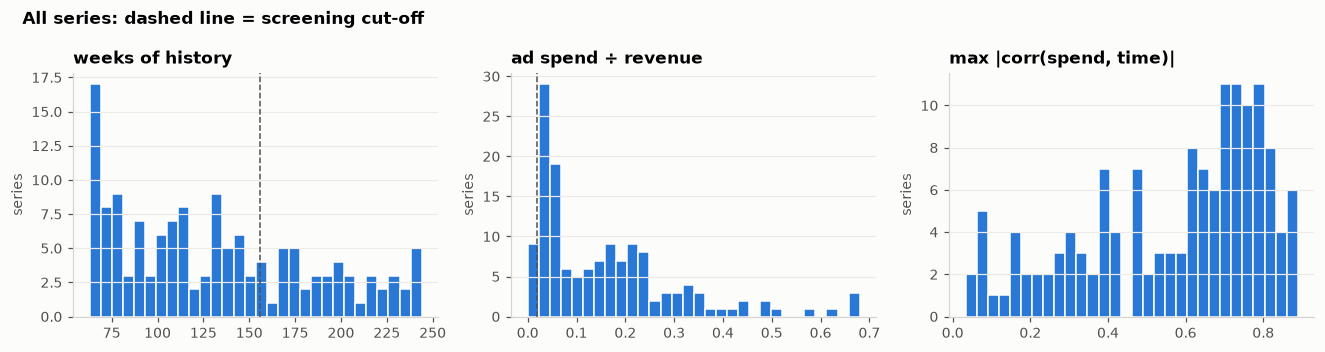

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, cut, label in [
    (axes[0], "weeks", 156, "weeks of history"),
    (axes[1], "spend_to_revenue", 0.02, "ad spend ÷ revenue"),
    (axes[2], "max_trend_corr", None, "max |corr(spend, time)|"),
]:
    ax.hist(screen[col].clip(upper=screen[col].quantile(0.98)), bins=30, color="#2a78d6", edgecolor="white")
    if cut is not None:
        ax.axvline(cut, color=TEXT_SECONDARY, ls="--", lw=1)
    ax.set_title(label); ax.set_ylabel("series")
fig.suptitle("All series: dashed line = screening cut-off", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

**Notice the trend correlation:** for most series, at least one main channel has
|corr(spend, time)| above 0.6. Brands tend to grow their ad budgets as they grow. This
is the same trap we planted with *social* in the synthetic data, and here it's
everywhere. We keep these series, but it tells us the trend term and those channels
will be hard to separate.

## 5. Real-data trap: Google Shopping became Performance Max

In 2022 Google migrated Smart Shopping campaigns into **Performance Max**. In many
brands, "shopping" spend falls just as "pmax" spend rises. The low *correlation*
between the two columns hides the problem: they're really **one channel that changed
name**. Modelled as two channels, each has only half the history and a level shift
right at the switch.

18 of 33 candidates have both shopping and PMax as main channels


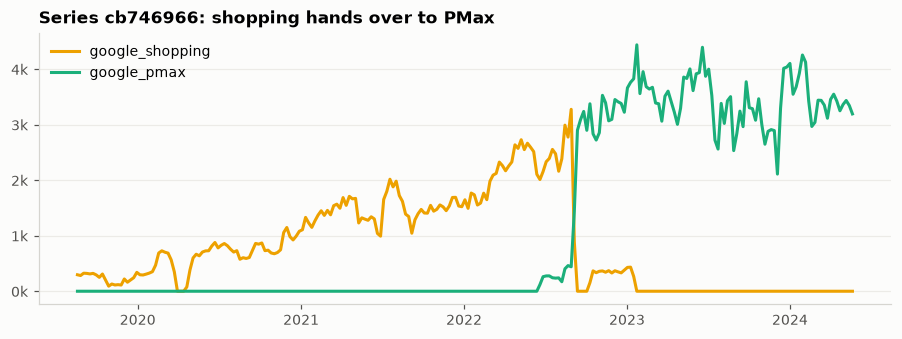

In [8]:
shop_pmax = cands[cands.main_channels.str.contains("google_shopping")
                  & cands.main_channels.str.contains("google_pmax")]
sid = shop_pmax.iloc[0].mmm_timeseries_id
g = weekly[weekly.mmm_timeseries_id == sid].set_index("week")
fig, ax = plt.subplots(figsize=(10, 3.2))
for c in ["google_shopping", "google_pmax"]:
    ax.plot(g.index, g[f"{c}_spend"], color=REAL_CHANNEL_COLORS[c], label=c)
ax.set_title(f"Series {sid[:8]}: shopping hands over to PMax"); ax.yaxis.set_major_formatter(money)
ax.legend()
print(f"{len(shop_pmax)} of {len(cands)} candidates have both shopping and PMax as main channels")

**Decision for modelling:** merge `google_shopping` and `google_pmax` into one
`google_shopping_pmax` channel whenever a brand shows this hand-over.

## 6. Deep dive: a Facebook + Instagram brand

The candidates whose main channels are Facebook and Instagram are the closest to the
"FB/IG ads plus a website" setup. We take the one with the longest history.

In [9]:
meta = cands[cands.main_channels == "meta_facebook, meta_instagram"].sort_values("weeks", ascending=False)
pick = meta.iloc[0]
SID = pick.mmm_timeseries_id
brand = weekly[weekly.mmm_timeseries_id == SID].set_index("week")
print(f"series {SID[:8]} | {pick.vertical} | {pick.territory} | {pick.currency} | "
      f"{pick.weeks} weeks ({pick.start} to {pick.end}) | spend = {pick.spend_to_revenue:.0%} of revenue")

series 1f064c83 | Apparel | All Territories | USD | 224 weeks (2020-02-10 to 2024-05-20) | spend = 22% of revenue


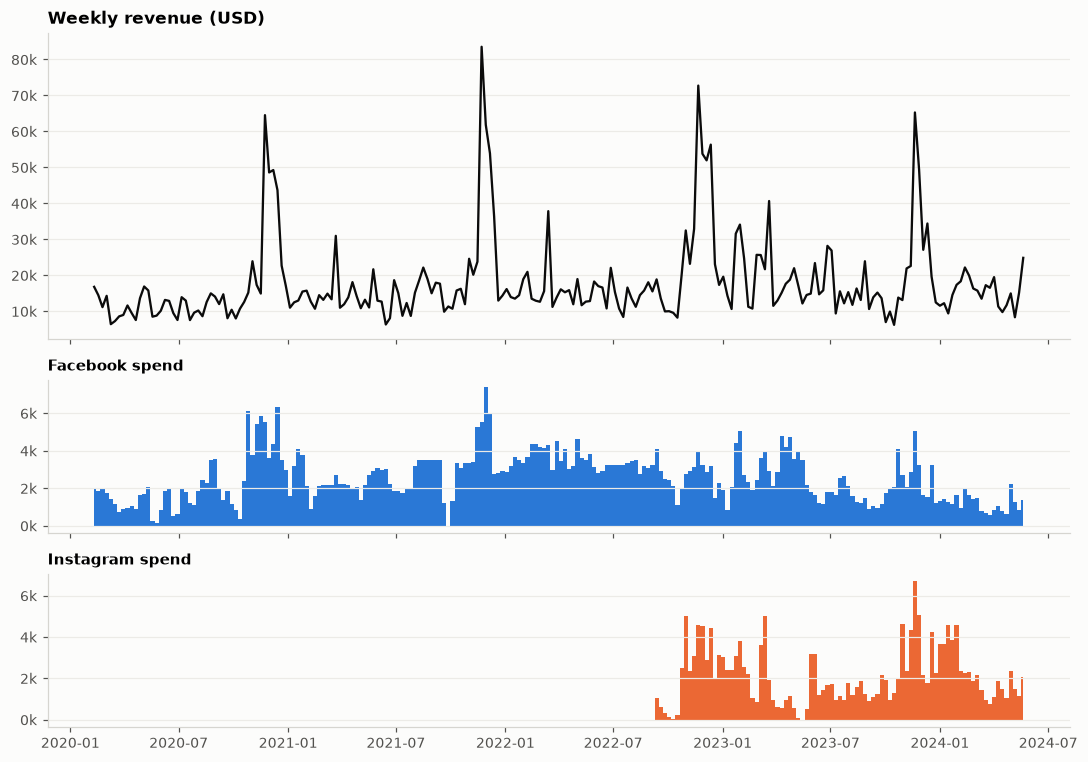

In [10]:
fb, ig = brand["meta_facebook_spend"], brand["meta_instagram_spend"]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
axes[0].plot(brand.index, brand["revenue"], color="#0b0b0b", lw=1.5)
axes[0].set_title(f"Weekly revenue ({pick.currency})")
axes[1].fill_between(brand.index, fb, step="mid", color=REAL_CHANNEL_COLORS["meta_facebook"], lw=0)
axes[1].set_title("Facebook spend", fontsize=10)
axes[2].fill_between(brand.index, ig, step="mid", color=REAL_CHANNEL_COLORS["meta_instagram"], lw=0)
axes[2].set_title("Instagram spend", fontsize=10)
for ax in axes: ax.yaxis.set_major_formatter(money)
fig.tight_layout()

### Does spend vary in ways the model can learn from?

In [11]:
t = np.arange(len(brand))
summary = pd.DataFrame({
    "mean / week": [fb.mean(), ig.mean()],
    "CV (std/mean)": [fb.std() / fb.mean(), ig.std() / ig.mean()],
    "corr with time": [np.corrcoef(t, fb)[0, 1], np.corrcoef(t, ig)[0, 1]],
    "zero weeks": [(fb == 0).sum(), (ig == 0).sum()],
}, index=["facebook", "instagram"])
print(f"corr(facebook, instagram) = {fb.corr(ig):.2f}")
summary

corr(facebook, instagram) = -0.07


,mean / week,CV (std/mean),corr with time,zero weeks
facebook,2545.46,0.51,-0.07,1
instagram,843.87,1.62,0.65,134


### Correlation is not causation

Below: weekly revenue against each channel's spend. A positive slope is **not** an
ROI. The brand might spend more *when it expects to sell more* (seasonal peaks,
launches). Spend follows demand, which is **reverse causality** (or *endogeneity*).
The MMM's controls, priors and, ideally, an experiment are what turn this into a
causal estimate.

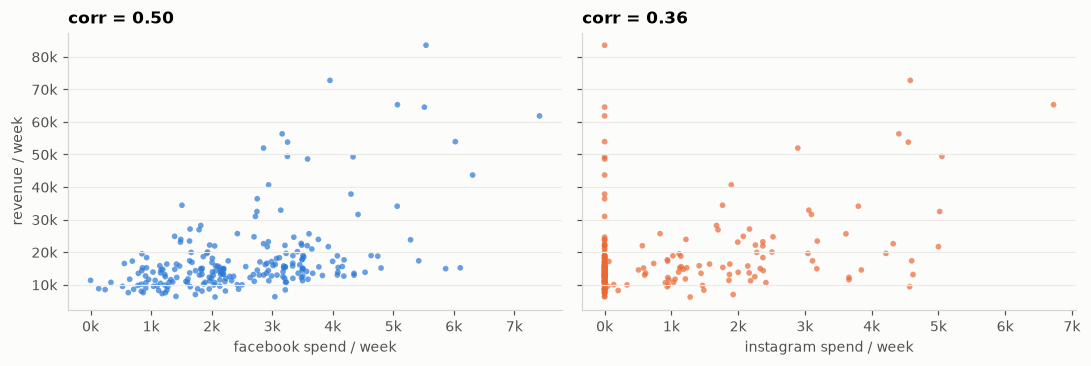

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, s, c in [(axes[0], fb, "meta_facebook"), (axes[1], ig, "meta_instagram")]:
    ax.scatter(s, brand["revenue"], s=14, color=REAL_CHANNEL_COLORS[c], alpha=0.7, edgecolor="none")
    ax.set_xlabel(f"{c.split('_')[1]} spend / week"); ax.xaxis.set_major_formatter(money)
    ax.set_title(f"corr = {s.corr(brand['revenue']):.2f}")
axes[0].set_ylabel("revenue / week"); axes[0].yaxis.set_major_formatter(money)
fig.tight_layout()

### Seasonality and the role of organic traffic

corr(revenue, organic clicks per channel):
direct_clicks            0.58
branded_search_clicks    0.65
organic_search_clicks    0.70
email_clicks             0.61
referral_clicks          0.69
all_other_clicks         0.25


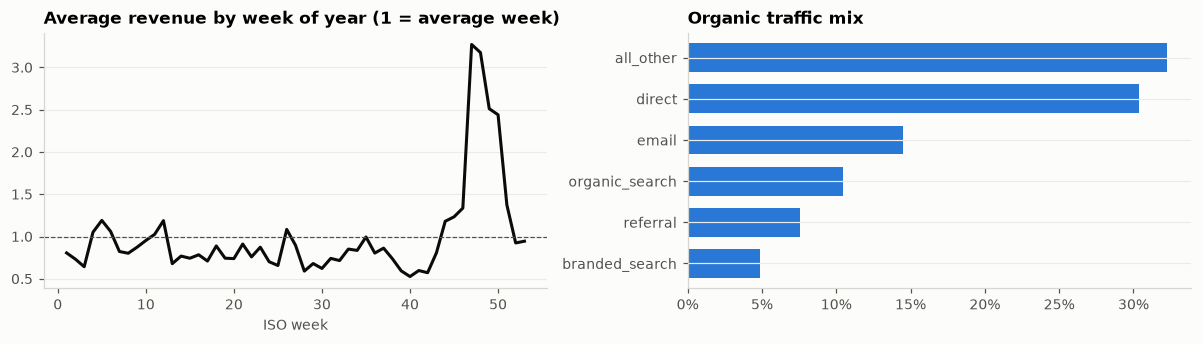

In [13]:
by_week = brand.groupby(brand.index.isocalendar().week.values)["revenue"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(by_week.index, by_week.values / by_week.mean(), color="#0b0b0b")
axes[0].axhline(1, color=TEXT_SECONDARY, lw=0.8, ls="--")
axes[0].set_title("Average revenue by week of year (1 = average week)"); axes[0].set_xlabel("ISO week")
organic = brand[ORGANIC_COLS].sum()
(organic / organic.sum()).sort_values().rename(lambda c: c.removesuffix("_clicks")).plot.barh(
    ax=axes[1], color="#2a78d6", width=0.7)
axes[1].set_title("Organic traffic mix"); axes[1].grid(axis="x")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.tight_layout()
print("corr(revenue, organic clicks per channel):")
print(brand[ORGANIC_COLS].corrwith(brand["revenue"]).round(2).to_string())

**Careful with organic traffic as a control.** Branded search and direct visits are
partly *caused by* ads: someone sees an Instagram ad, then later googles the brand.
Using them as controls would soak up part of the ad effect, a **"bad control"**
(a *mediator*). They're safe to use only for traffic that ads don't drive, such as
email, which the brand controls itself.

In [14]:
# Saved for step 1.6; data/ is gitignored for CSVs.
out = brand.reset_index()[["week", "revenue", "orders", "meta_facebook_spend", "meta_instagram_spend",
                           *ORGANIC_COLS]]
out.to_csv(mbc.realdata.conjura.RAW_PATH.parents[2] / "conjura_meta_brand_weekly.csv", index=False)
print(f"saved {len(out)} weeks for series {SID[:8]}")

saved 224 weeks for series 1f064c83


## 7. Takeaways

**The dataset as a whole**
- **Most real series are too short.** The median is 124 weeks, and only 33 of 142
  series pass the basic screen. Three years of clean weekly data is a lot to ask of a
  real business.
- **Google Shopping → PMax affects 18 of the 33 candidates.** It's one channel with a
  rename partway through, so we merge it before modelling. Data lineage matters as
  much as statistics.
- **Spend that follows the trend is everywhere** (max |corr(spend, time)| is mostly
  above 0.6). Brands grow their budgets as they grow, so trend and media will be hard
  to separate.

**The chosen brand** (`1f064c83`: apparel, USD, 224 weeks, ads = 22% of revenue)
- **Q4 dominates revenue.** Weeks 47–50 average about 3× a normal week. **Facebook
  spend also peaks in Q4**: the brand spends more when it expects to sell more. The
  raw correlation (0.50) mixes ad effect with seasonality. It's the *TV + holidays*
  trap from our synthetic data, but here the brand created it. Holiday controls must
  absorb the peak, or Facebook gets credit for Black Friday.
- **Instagram only starts in September 2022:** about 90 weeks of history, with 134 zero
  weeks before that. Its correlation with time (0.65) comes from the launch, not from
  growth. Expect a wide uncertainty interval for Instagram, and note that its first
  Q4 coincides with its launch.
- **Facebook and Instagram are not correlated (−0.07)**, which is good: in the
  period when both run, the model can split credit between them.
- **Organic traffic is a trap, not a free control.** Direct, branded and organic
  clicks correlate 0.6–0.7 with revenue, but ads partly *cause* that traffic. Using it
  as a control would hide part of the ad effect.

**Modelling decisions for step 1.6**

| decision | choice | why |
|---|---|---|
| target | weekly revenue (before discount) | discounts leak information, per the data dictionary |
| channels | Facebook, Instagram | the only main channels for this brand |
| controls | Black Friday / Cyber week, Christmas weeks, yearly Fourier, trend | absorb Q4 so it isn't credited to ads |
| left out | organic clicks, discounts | mediators and leakage |
| holdout | last 12 weeks | same as synthetic |
| before trusting it | semi-synthetic check on *these* spend series | can Instagram's short history identify its effect at all? |
